# Icefields Parkway flyover, step by step

How the flight from Lake Louise to the Columbia Icefield was made with [forge3d](https://github.com/milos-agathon/forge3d) 1.40.1, using the project's own scripts (`scripts/config.py`, `prep.py`, `flight.py`, `render.py`). It's a sibling of the Yosemite flyover, scaled up: a 100 km scene instead of 23 km, built from global data (Copernicus and Sentinel-2) because USGS stops at the border.

1. The terrain: a 100 km box of Copernicus elevation, and what the viewer meshes
2. The imagery: one nearly cloud-free Sentinel-2 pass, and two fixes in `prep.py` (shadowed lakes, smeared cliffs)
3. The flight: keyframes, speeds, lenses and clearance
4. The light: why this scene drops the shadow map, and turns the Sun down
5. Frames from the flight

## Setup

Run `pixi run data` and `pixi run prep` first: this notebook reads the DEM and the graded imagery in `data/` (and the ungraded tiles for section 2). Sections 1–4 need no renderer; section 5 opens forge3d's viewer (a GPU, or on Linux Mesa's software Vulkan under `xvfb-run`).

In [1]:
WIDTH = 960          # frame width for section 5 (16:9); the film is 1920
LITE = True          # 4x antialiasing instead of 8x (render.py --lite)
STILLS = [0.0, 23.5, 37.2, 92.4]   # seconds: Lake Louise, Bow Lake, Peyto Lake, the icefield

In [2]:
import math, sys, time
from pathlib import Path

import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
import matplotlib.patheffects as pe
from PIL import Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "config.py").exists())
sys.path.insert(0, str(ROOT / "scripts"))
import config, prep, flight
import forge3d as f3d

%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"pil_kwargs": {"quality": 85}, "bbox_inches": "tight"}
plt.rcParams.update({"figure.dpi": 100, "font.size": 9})
Image.MAX_IMAGE_PIXELS = None
print("forge3d", f3d.__version__)

PLACES = {"Lake Louise": (51.4117, -116.2281), "Bow Lake": (51.6644, -116.4486), "Peyto Lake": (51.7250, -116.5222),
          "Saskatchewan Crossing": (51.9744, -116.7456), "Athabasca Glacier": (52.1986, -117.2436),
          "Mount Columbia": (52.1475, -117.4417)}
def utm(lat, lon):
    x, y = flight.to_utm(lat, lon)
    return float(x[0]), float(y[0])

forge3d 1.40.1


## 1. The terrain

USGS stops at the border, so the elevation is the global **Copernicus GLO-30** DEM (from TanDEM-X radar, served from an open AWS bucket), reprojected to 25 m in UTM zone 11N. The box runs from south of Lake Louise to north of the Columbia Icefield, with room either side for the horizon.

DEM 3903 x 4331 cells at 25 m = 97.6 x 108.3 km, 744-3683 m
forge3d meshes a square grid at most 2048 a side: a vertex every 48 m east-west and 53 m north-south (the DEM is 25 m)


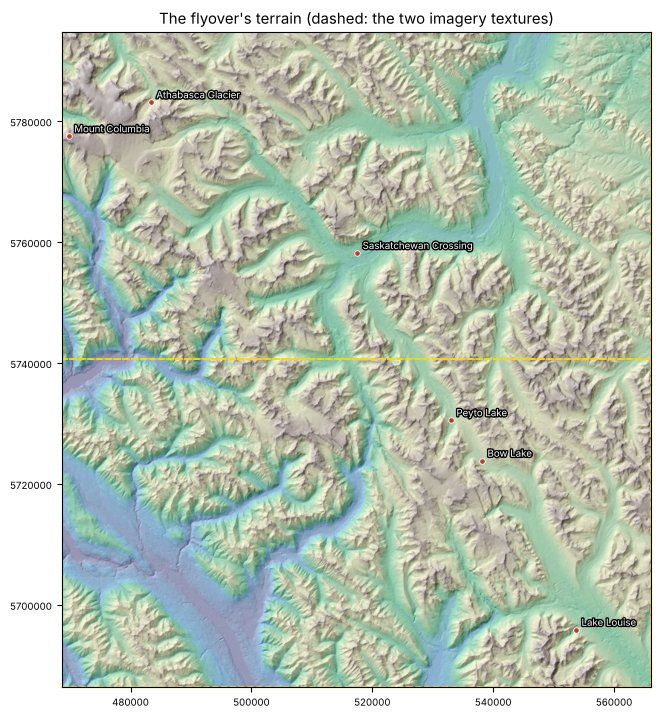

In [3]:
with rasterio.open(config.DEM) as src:
    dem = src.read(1)
k = 4
z = dem[::k, ::k]
W_km, H_km = (config.RIGHT - config.LEFT) / 1000, (config.TOP - config.BOTTOM) / 1000
print(f"DEM {dem.shape[1]} x {dem.shape[0]} cells at {config.DEM_RES:g} m = {W_km:.1f} x {H_km:.1f} km, "
      f"{dem.min():.0f}-{dem.max():.0f} m")
span = max(config.RIGHT - config.LEFT, config.TOP - config.BOTTOM)
print(f"forge3d meshes a square grid at most 2048 a side: a vertex every {(config.RIGHT - config.LEFT) / 2047:.0f} m east-west "
      f"and {(config.TOP - config.BOTTOM) / 2047:.0f} m north-south (the DEM is {config.DEM_RES:g} m)")

ext = (config.LEFT, config.RIGHT, config.BOTTOM, config.TOP)
shade = LightSource(azdeg=315, altdeg=40).hillshade(z, vert_exag=1.0, dx=config.DEM_RES * k, dy=config.DEM_RES * k)

def base_map(ax, labels=True):
    ax.imshow(shade, cmap="gray", extent=ext)
    ax.imshow(z, cmap="terrain", alpha=0.3, extent=ext)
    if labels:
        for name, (la, lo) in PLACES.items():
            x, y = utm(la, lo)
            ax.plot(x, y, "o", ms=4, color="#c0392b", mec="white", mew=0.6)
            ax.annotate(name, (x, y), xytext=(4, 3), textcoords="offset points", fontsize=7, color="white",
                        path_effects=[pe.withStroke(linewidth=2, foreground="black")])
    ax.ticklabel_format(useOffset=False, style="plain"); ax.tick_params(labelsize=7)

fig, ax = plt.subplots(figsize=(8, 8.5))
base_map(ax)
for p_, l_, t_, r_, b_ in config.image_tiles():
    ax.add_patch(plt.Rectangle((l_, b_), r_ - l_, t_ - b_, fill=False, ec="gold", lw=1.2, ls="--"))
ax.set_title("The flyover's terrain (dashed: the two imagery textures)")
plt.show()

At about 50 m a vertex the mesh is far coarser than Yosemite's, but for a flight 0.4–2 km above the ground over a 100 km scene, that's the right trade: the peaks and valleys read, and the detail comes from the imagery.

## 2. The imagery

The colour is **Sentinel-2** true colour at 12 m, from the nearly cloud-free pass of 25 September 2025 (golden larch season), with any cloudy gaps filled from other late-summer passes using Sentinel-2's own scene classification. It's split into a north and a south texture to keep each a sensible size.

A satellite passes mid-morning and looks straight down, which causes two problems once the image is draped on 3D terrain and lit by an evening Sun. `prep.py` fixes both:

- **Lakes.** A ridge's morning shadow, or a little haze, lies across some of the glacial lakes. For each clearly turquoise patch of water, `prep.lakes` finds the lake's level from the DEM, gathers the dark, bluish pixels joined to it at that same level, and repaints them in the lake's own median colour.
- **Cliffs.** Steep faces (a blend from 45° to 65°, at most three-quarters strength) lean toward the grey of Rockies limestone, keeping some of the photo's light and dark, so the renderer's Sun can light them. Ice and snow are left alone.

Here's Peyto Lake, before and after:

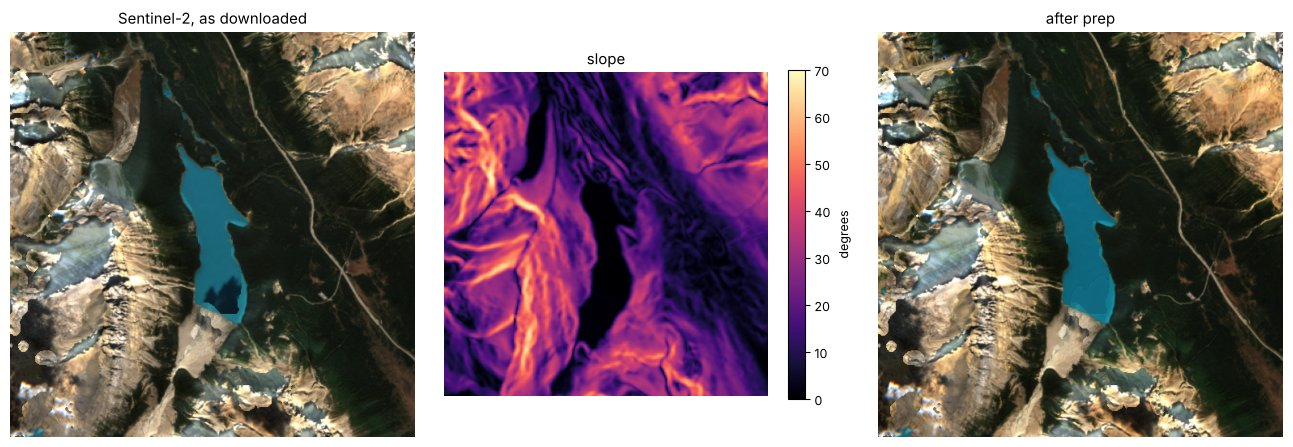

In [4]:
tiles = config.image_tiles()
px_, py_ = utm(*PLACES["Peyto Lake"])
for p_, l_, t_, r_, b_ in tiles:
    if b_ <= py_ <= t_:
        tile = (p_, l_, t_)
p_, l_, t_ = tile
half = 3000
box = (int((px_ - half - l_) / config.IMAGE_RES), int((t_ - (py_ + half)) / config.IMAGE_RES),
       int((px_ + half - l_) / config.IMAGE_RES), int((t_ - (py_ - half)) / config.IMAGE_RES))
raw = Image.open(p_).crop(box)
grd = Image.open(config.graded(p_)).crop(box)
slope = prep.slope_deg()
rr = int((config.TOP - (py_ + half)) / config.DEM_RES); cc = int((px_ - half - config.LEFT) / config.DEM_RES)
sl = slope[rr:rr + int(2 * half / config.DEM_RES), cc:cc + int(2 * half / config.DEM_RES)]
fig, axs = plt.subplots(1, 3, figsize=(13, 4.4))
axs[0].imshow(raw); axs[0].set_title("Sentinel-2, as downloaded")
im = axs[1].imshow(sl, cmap="magma", vmin=0, vmax=70); axs[1].set_title("slope"); plt.colorbar(im, ax=axs[1], shrink=0.8, label="degrees")
axs[2].imshow(grd); axs[2].set_title("after prep")
for ax in axs: ax.axis("off")
plt.tight_layout(); plt.show()

## 3. The flight

Twelve keyframes in `flight.KEYS`, each an eye point and an aim point (latitude, longitude, altitude), a speed and a lens. It's the same machinery as the Yosemite flight: a Catmull-Rom spline for the eye, times from the speeds (each stretch takes its length divided by the average of its two speeds), a monotone spline from time to distance so the camera never backs up, a 3-second hold at the end. Two things scale with the bigger scene: the speeds (over 2,000 m/s down the long valleys, easing to under 300 m/s over Peyto Lake), and the clearance, which keeps the eye at least 200 m above the highest ground within 300 m (Yosemite used 110 m within 150 m).

In [5]:
f = flight.plan(dem)
flight.report(f)

2863 frames, 95 s at 30 fps
    0.0 s  Lake Louise              241 m/s  lens  40    624 m up
    7.2 s  out of Lake Louise       846 m/s  lens  50   1532 m up
   16.4 s  Bow Valley, Hector Lake  1502 m/s  lens  50   1639 m up
   23.5 s  Crowfoot Glacier, Bow Lake  1134 m/s  lens  48   1210 m up
   33.0 s  Bow Summit               397 m/s  lens  42    592 m up
   37.2 s  Peyto Lake               290 m/s  lens  40    422 m up
   43.2 s  over Peyto Lake          458 m/s  lens  44    795 m up
   54.6 s  Mistaya valley          1548 m/s  lens  50   1496 m up
   63.3 s  Saskatchewan Crossing   2100 m/s  lens  50   2110 m up
   73.8 s  Big Bend, Sunwapta Pass  1616 m/s  lens  48   1900 m up
   85.8 s  Athabasca Glacier        526 m/s  lens  42   1476 m up
   92.4 s  Columbia Icefield, hold     3 m/s  lens  38   1194 m up
  lowest: 421 m above the ground at 37.1 s; path raised by up to 114 m to clear the terrain


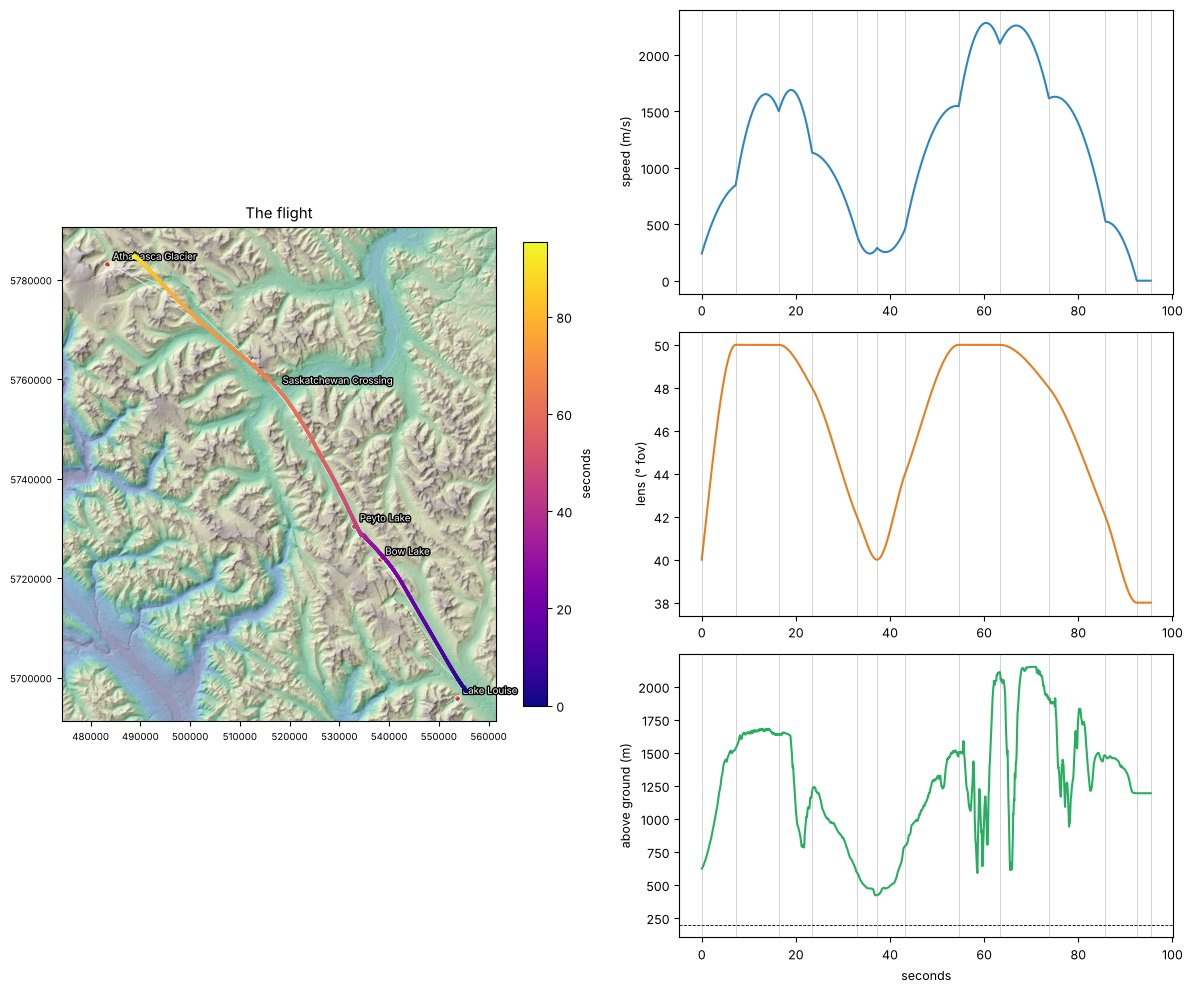

In [6]:
fig = plt.figure(figsize=(12, 10))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1], width_ratios=[1.1, 1])
ax = fig.add_subplot(gs[:, 0]); base_map(ax)
sc = ax.scatter(f.eye[:, 0], f.eye[:, 1], c=f.t, cmap="plasma", s=2, zorder=3)
for i in range(0, len(f.t), flight.FPS * 4):
    ax.plot([f.eye[i, 0], f.aim[i, 0]], [f.eye[i, 1], f.aim[i, 1]], color="white", lw=0.5, alpha=0.7)
pad = 6000
ax.set_xlim(min(f.eye[:, 0].min(), f.aim[:, 0].min()) - pad, max(f.eye[:, 0].max(), f.aim[:, 0].max()) + pad)
ax.set_ylim(f.eye[:, 1].min() - pad, f.eye[:, 1].max() + pad)
plt.colorbar(sc, ax=ax, shrink=0.5, label="seconds"); ax.set_title("The flight")
a1 = fig.add_subplot(gs[0, 1]); a1.plot(f.t, f.speed, color="#2e86c1"); a1.set_ylabel("speed (m/s)")
a2 = fig.add_subplot(gs[1, 1], sharex=a1); a2.plot(f.t, f.fov, color="#e67e22"); a2.set_ylabel("lens (° fov)")
a3 = fig.add_subplot(gs[2, 1], sharex=a1); a3.plot(f.t, f.clearance, color="#27ae60")
a3.axhline(flight.MIN_CLEARANCE, color="k", lw=0.6, ls="--"); a3.set_ylabel("above ground (m)"); a3.set_xlabel("seconds")
for a in (a1, a2, a3):
    for t0 in f.key_t: a.axvline(t0, color="grey", lw=0.4, alpha=0.6)
plt.tight_layout(); plt.show()

## 4. The light

The Sun is placed for 25 September 2025 at 5:45 pm MDT, low in the west-south-west. Two choices in `render.py` differ from Yosemite, both because of the scene's size and its colours:

- **No shadow map.** A shadow map spread over 100 km has texels tens of metres across, which left blocky grey patches on flat ground like the lakes. Shadows come instead from `sun_visibility`, which traces toward the Sun through the heightfield (out to 20 km here).
- **A gentle Sun and a strong sky light.** forge3d's Sun adds a specular sheen that doesn't depend on the ground's colour, so at full strength it turned dark forest and deep lakes pale grey wherever they faced the light. The Sun runs at 0.4 with ambient light at 0.5, so the lighting mostly scales the imagery's own colours.

In [7]:
import render as R
sun = f3d.sun_position_utc(*config.SUN_LATLON, *config.SUN_UTC)
print(f"Sun at 5:45 pm MDT, 25 Sept 2025: azimuth {sun.azimuth:.1f}°, {sun.elevation:.1f}° up")
print(f"sun intensity {R.SUN_INTENSITY}, ambient {R.TERRAIN['ambient']}, shadow technique: {R.PBR['shadow_technique']}, "
      f"sun visibility out to {R.PBR['sun_visibility']['max_distance'] / 1000:.0f} km")

Sun at 5:45 pm MDT, 25 Sept 2025: azimuth 246.4°, 16.0° up
sun intensity 0.4, ambient 0.5, shadow technique: none, sun visibility out to 20 km


## 5. Frames from the flight

One viewer: the DEM, the two graded Sentinel-2 textures as overlays, the Sun and the PBR settings above. For each frame the camera is set from the flight and the viewer takes a snapshot; `render.finish` then paints the evening sky into the viewer's plain background, lifts the colour, warms the highlights, cools the shadows and adds a little haze along the skyline.

In [8]:
size = (WIDTH, WIDTH * 9 // 16)
min_h = float(dem.min())
out = config.OUT / "notebook"; out.mkdir(parents=True, exist_ok=True)
pbr = dict(R.PBR, **R.LITE) if LITE else dict(R.PBR)
frames = [min(int(round(s * flight.FPS)), len(f.t) - 1) for s in STILLS]
t0 = time.time()
v = R.open_viewer(out / "viewer.log", width=size[0], height=size[1], terrain_path=str(config.DEM),
                  fov_deg=flight.FOV, title="Icefields Parkway")
shots = []
try:
    for j, (p_, l_, t_, r_, b_) in enumerate(config.image_tiles()):
        v.load_overlay(f"sentinel2_{j}", config.graded(p_), extent=R.uv(l_, t_, r_, b_), z_order=j,
                       preserve_colors=R.PRESERVE_COLORS)
    v.send_ipc({"cmd": "set_terrain_sun", "azimuth_deg": float(sun.azimuth), "elevation_deg": float(sun.elevation),
                "intensity": R.SUN_INTENSITY})
    v.send_ipc({"cmd": "set_terrain_pbr", **pbr})
    v.send_ipc({"cmd": "set_terrain", **R.TERRAIN})
    v.send_ipc(flight.camera(f.eye[frames[0]], f.aim[frames[0]], min_h, float(f.fov[frames[0]])))
    time.sleep(2.0)
    for i in frames:
        v.send_ipc(flight.camera(f.eye[i], f.aim[i], min_h, float(f.fov[i])))
        p = out / f"raw_{f.t[i]:05.1f}s.png"
        v.snapshot(p, *size)
        shots.append((i, p))
finally:
    v.close()
print(f"{len(shots)} frames in {time.time() - t0:.0f} s")

4 frames in 83 s


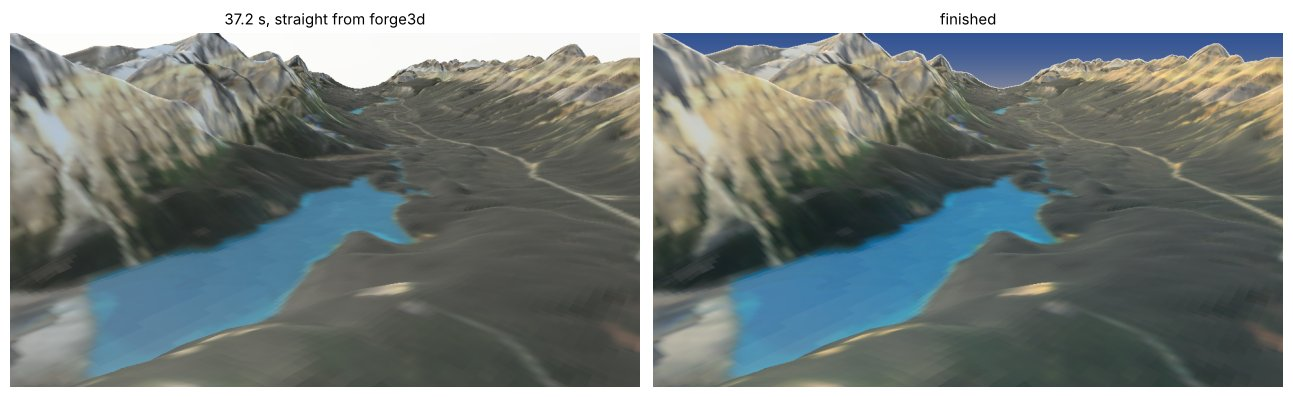

In [9]:
i, p = shots[2]
fig, axs = plt.subplots(1, 2, figsize=(13, 3.9))
axs[0].imshow(Image.open(p)); axs[0].set_title(f"{f.t[i]:.1f} s, straight from forge3d")
axs[1].imshow(R.finish(p)); axs[1].set_title("finished")
for ax in axs: ax.axis("off")
plt.tight_layout(); plt.show()

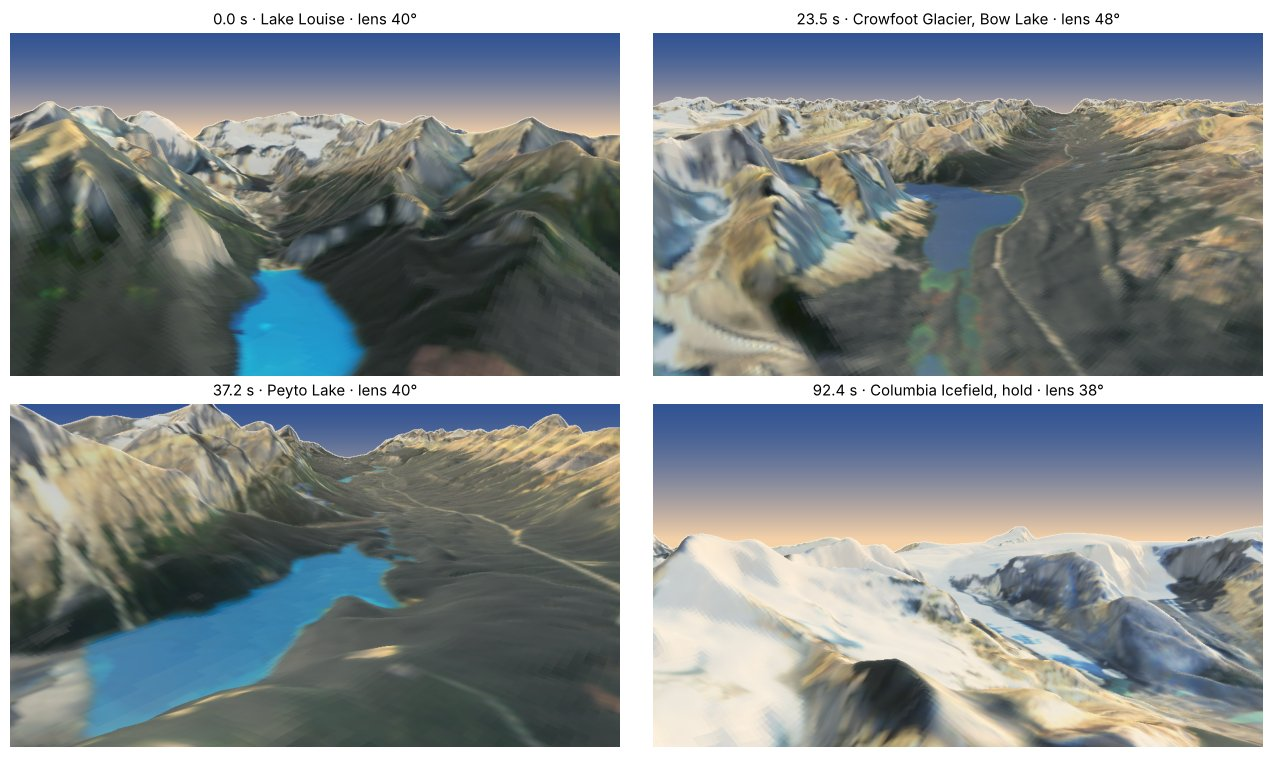

In [10]:
names = {round(t0, 1): kk[4] for t0, kk in zip(f.key_t, flight.KEYS)}
fig, axs = plt.subplots(2, 2, figsize=(13, 7.6))
for ax, (i, p) in zip(axs.ravel(), shots):
    ax.imshow(R.finish(p)); ax.axis("off")
    near = min(names, key=lambda t0: abs(t0 - f.t[i]))
    ax.set_title(f"{f.t[i]:.1f} s · {names[near] if abs(near - f.t[i]) < 2 else ''} · lens {f.fov[i]:.0f}°")
plt.tight_layout(); plt.show()

The whole film is `pixi run render`, piped frame by frame from the viewer into ffmpeg (`out/icefields_parkway_flyover.mp4`).

Data: Copernicus GLO-30 DEM (ESA / Copernicus Programme, via AWS open data); Sentinel-2 L2A (ESA Copernicus, via Element 84's Earth Search). Rendering: [forge3d](https://github.com/milos-agathon/forge3d) by Milos Popovic.